# Notes
* July 28
* Clarify math $R_0 - \tau \cdot R_1$

In [145]:
import random
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import pandas as pd
pd.options.plotting.backend = 'plotly'
from networkx.algorithms.community import modularity
import networkx as nx
import scipy
import numpy as np

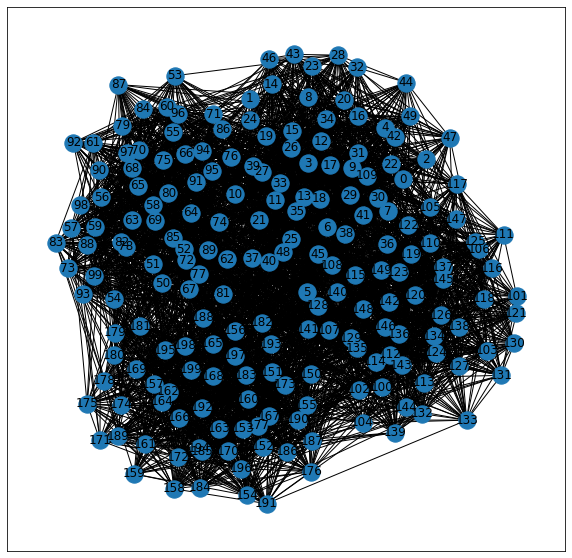

In [201]:
# G = nx.barbell_graph(3, 2)

name = 'SBM-50-4-50-2'
nodes_per_group, num_groups = 50, 4
p_in, p_out = 0.5, 0.1
probs = np.ones(shape=(num_groups, num_groups)) * p_out
np.fill_diagonal(probs, p_in)
G = nx.stochastic_block_model(sizes=[nodes_per_group] * num_groups, p=probs, seed=0)

fig, ax = plt.subplots(figsize=(10, 10))
nx.draw_networkx(G, pos=nx.spring_layout(G), ax=ax)

In [202]:
n, m = G.order(), G.size()
A = nx.adjacency_matrix(G, nodelist=sorted(G.nodes))

/var/folders/bv/qy_7zyfs48q48fx77c1yxd5c0000gn/T/ipykernel_34112/2411525078.py:2: FutureWarning:

adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.



## Eq 16
$$R^0 = 2(A - A^\prime)$$
$$R^1 = 4A^2 - 2(A^\prime\, A + A\, A^\prime)$$

In [223]:
1/23

0.043478260869565216

In [222]:
D

array([[23.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0., 16.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0., 29., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ..., 30.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0., 33.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0., 30.]])

In [221]:
np.linalg.inv(D)

array([[0.04347826, 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.0625    , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.03448276, ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.03333333, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.03030303,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.03333333]])

In [224]:
def get_Rs(A, kind='graph-walk_cont'):
    n = A.shape[0]
    d = A * np.ones((n, 1))   # degree vector
    D = np.diag(A * np.ones(n))

    A_prime = (d * np.transpose(d)) / (2 * m)


    if kind == 'graph-walk_cont':  # Eq 15 and 17 TODO: why the negative sign?
        R_0 = -2 * (A - A_prime)  # no negative sign?
        R_1 = 4 * A * A - 2 * (A * A_prime + A_prime * A)

    elif kind == 'diffusion_cont':  # eq 20, 22
        R_0 = -2 * (A - A_prime)
        R_1 = 4 * A * A - 2 * D * A - 2 * A * D - 2 * A * A_prime - 2 * A_prime * A

    elif kind == 'random-walk_cont':  # eq 27, 29
        D_inv = np.linalg.inv(D)
        R_0 = ((A - A_prime) * D_inv + D_inv * (A - A_prime)) * -1
        R_1 = 0
    return R_0, R_1

In [204]:
def get_communities(R):
    ## initialize communities
    R = R * -1  # to maximize

    n = R.shape[0]
    communities = [{u} for u in range(n)]  # list of sets
    # node2comm = {u: u for u in range(n)}  # maps nodes -> clusters

    iters = 0
    max_iters = 100
    changed = True

    while changed and iters < max_iters:
        iters += 1
        changed = False
        nodes = list(range(n))
        random.shuffle(nodes)
        for i in nodes:  # try all nodes  # TODO: replace with random shuffle
            current_comm_i_idx = [ix for ix, comm in enumerate(communities) if i in comm][0]

            loss_i_from_current_comm = 0  # loss from i leaving its current comm
            for j in communities[current_comm_i_idx]:
                if i != j:
                    loss_i_from_current_comm -= R[i, j]

            new_comm_i = None
            gain_i_to_new_comm = 0

            for comm_ix, community in enumerate(communities):  # iterate over all communities
                g = 0
                for j in community:
                    g += R[i, j]

                if g > gain_i_to_new_comm:
                    gain_i_to_new_comm = g
                    new_comm_i = comm_ix

            modularity_change = gain_i_to_new_comm + loss_i_from_current_comm

            if new_comm_i is not None and modularity_change > 0 and current_comm_i_idx != new_comm_i:
                # remove i from old comm, add it to the new comm
                changed = True
                communities[new_comm_i].add(i)
                communities[current_comm_i_idx].remove(i)

                if len(communities[current_comm_i_idx]) == 0:
                    del communities[current_comm_i_idx]
    return communities

In [243]:
modularity?

In [254]:
R0, R1 = R=get_Rs(A, kind='random-walk_cont')
comms = get_communities(R=R0)
Q = modularity(G, comms)
print(f'{len(comms)=} {Q=:.3f}')

len(comms)=4 Q=0.362


In [255]:
R0

matrix([[ 0.00975488,  0.00862931,  0.00987994, ...,  0.01063032,
          0.01025513,  0.01088044],
        [ 0.00862931,  0.00750375,  0.00875438, ...,  0.00950475,
          0.00912956,  0.00975488],
        [ 0.00987994,  0.00875438,  0.010005  , ...,  0.01075538,
          0.01038019, -0.03482783],
        ...,
        [ 0.01063032,  0.00950475,  0.01075538, ...,  0.01150575,
         -0.03386438, -0.03081659],
        [ 0.01025513,  0.00912956,  0.01038019, ..., -0.03386438,
          0.01075538, -0.03270846],
        [ 0.01088044,  0.00975488, -0.03482783, ..., -0.03081659,
         -0.03270846,  0.012006  ]])

In [253]:
R0

matrix([[ 0.38044022,  0.29264632,  0.3901951 , ...,  0.44872436,
          0.41945973,  0.46823412],
        [ 0.29264632,  0.22511256,  0.30015008, ...,  0.34517259,
          0.32266133,  0.36018009],
        [ 0.3901951 ,  0.30015008,  0.4002001 , ...,  0.46023012,
          0.43021511, -1.51975988],
        ...,
        [ 0.44872436,  0.34517259,  0.46023012, ...,  0.52926463,
         -1.50525263, -1.44772386],
        [ 0.41945973,  0.32266133,  0.43021511, ..., -1.50525263,
          0.46248124, -1.48374187],
        [ 0.46823412,  0.36018009, -1.51975988, ..., -1.44772386,
         -1.48374187,  0.57628814]])

In [215]:
rows = []
kinds = ['graph-walk_cont', 'diffusion_cont']

for kind in tqdm(kinds):
    R_0, R_1 = get_Rs(A, kind=kind)
    for tau in np.logspace(-3, -1.75, 50):
        # tau /= 100
        R = R_0 - (tau * R_1)
        comms = get_communities(R=R)
        Q = modularity(G, comms)
        rows.append(dict(name=name, kind=kind, tau=tau, clusters=len(comms), Q=Q))

df = pd.DataFrame(rows)
df.head(2)

100%|██████████| 2/2 [00:15<00:00,  7.87s/it]


,name,kind,tau,clusters,Q
0,SBM-50-4-50-2,graph-walk_cont,0.00100,4,0.361537
1,SBM-50-4-50-2,graph-walk_cont,0.00106,4,0.361537


In [216]:
(
    df
    .sort_values(by='tau', ascending=False)
    .plot
    .line(x='tau', y='Q', color='kind', markers=True, hover_data=['clusters'], log_x=True)
)

In [213]:
(
    df
    .sort_values(by='tau', ascending=False)
    .plot
    # .bar('tau','tau') #, color='kind', hover_data=['Q'])
)

In [228]:
 nx.get_node_attributes(G, 'group')

{}

In [230]:
pos = nx.spring_layout(G)

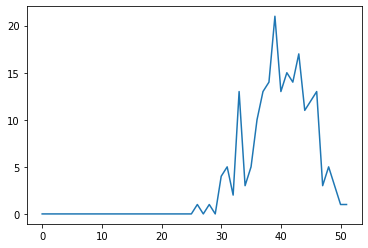

In [242]:
plt.plot(nx.degree_histogram(G));

In [249]:
original_clusters = {}
comm_orig = nx.get_node_attributes(G, 'block')
for u, c_u in comm_orig.items():
    if c_u not in original_clusters:
        original_clusters[c_u] = set()
    original_clusters[c_u].add(u)

print(f'{modularity(G, original_clusters.values()):.3f}')

0.362


Text(0.5, 1.0, 'Empirical')

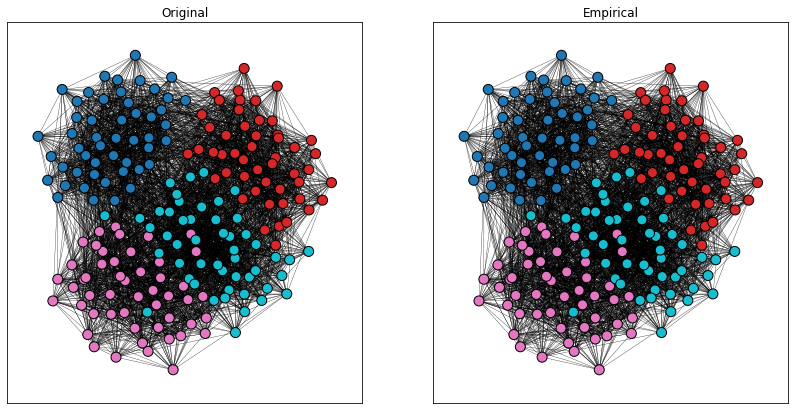

In [256]:
### Visualize the communities

comm_orig = nx.get_node_attributes(G, 'block')
cmap_m = plt.cm.get_cmap('tab10', max(comm_orig.values()) + 1)

comm_m = {}
for i in range(n):
    comm_m[i] = list(ix for ix, comm in enumerate(comms) if i in comm)[0]

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 7))
nx.draw_networkx_nodes(G, pos=pos, node_size=100,edgecolors='k',cmap=cmap_m, node_color=list(comm_orig.values()), ax=ax1)
nx.draw_networkx_edges(G, pos=pos, alpha=1,width=0.3, ax=ax1);
ax1.set_title('Original')

nx.draw_networkx_nodes(G, pos=pos, node_size=100, edgecolors='k', cmap=cmap_m, node_color=list(comm_m.values()),
                       ax=ax2)
nx.draw_networkx_edges(G, pos=pos, alpha=1, width=0.3, ax=ax2);
ax2.set_title('Empirical');

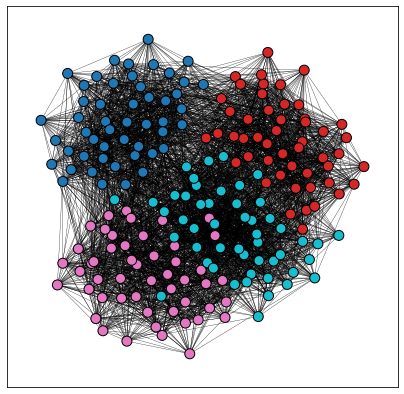

In [232]:
### Visualize the communities

plt.figure(figsize=[7,7])
nx.draw_networkx_nodes(G, pos=pos, node_size=100,edgecolors='k',cmap=cmap_m, node_color=list(comm_m.values()))
nx.draw_networkx_edges(G, pos=pos, alpha=1,width=0.3);

In [149]:
A * np.ones(n)

array([23., 16., 29., 31., 29., 26., 35., 30., 22., 34., 22., 30., 28.,
       28., 28., 29., 35., 24., 36., 35., 20., 22., 29., 30., 25., 26.,
       28., 28., 26., 24., 24., 25., 25., 29., 31., 26., 25., 28., 33.,
       29., 28., 32., 30., 24., 25., 27., 27., 30., 32., 29., 24., 29.,
       29., 27., 30., 21., 30., 27., 23., 25., 36., 29., 29., 28., 23.,
       26., 30., 24., 32., 30., 15., 26., 23., 20., 27., 27., 24., 26.,
       27., 25., 27., 29., 31., 31., 32., 23., 30., 22., 24., 35., 25.,
       31., 26., 32., 23., 28., 24., 25., 30., 23., 25., 34., 29., 22.,
       24., 26., 21., 27., 24., 21., 25., 31., 36., 24., 25., 30., 29.,
       23., 33., 27., 32., 29., 31., 26., 29., 25., 23., 18., 25., 33.,
       29., 21., 24., 30., 25., 32., 28., 27., 23., 27., 29., 30., 24.,
       26., 29., 19., 24., 32., 18., 29., 22., 35., 24., 36., 32., 28.,
       23., 32., 23., 23., 23., 27., 30., 27., 29., 28., 29., 23., 32.,
       31., 28., 25., 25., 27., 31., 26., 29., 29., 24., 29., 26

In [152]:
R0, R1 = get_Rs(A)
R0

matrix([[-0.1943424 , -0.09404849, -0.308964  , ..., -0.33063924,
         -0.40007348, -0.33063924],
        [-0.1943424 , -0.09404849, -0.308964  , ..., -0.33063924,
         -0.40007348, -0.33063924],
        [-0.1943424 , -0.09404849, -0.308964  , ..., -0.33063924,
         -0.40007348, -0.33063924],
        ...,
        [-0.1943424 , -0.09404849, -0.308964  , ..., -0.33063924,
          1.59992652,  1.66936076],
        [-0.1943424 , -0.09404849, -0.308964  , ...,  1.66936076,
         -0.40007348,  1.66936076],
        [-0.1943424 , -0.09404849, -0.308964  , ...,  1.66936076,
          1.59992652, -0.33063924]])